
# Phase 5: Confidence Evaluation

## Objective

The goal of this phase is to make the model's predictions more reliable and interpretable.

Instead of simply predicting whether a code submission was written by a human or AI, we also want to estimate how confident the model is in its prediction.

This phase has two main components:

1. **Probability Calibration:** Adjusting the model's predicted probabilities so that they better reflect actual outcomes.
2. **Confidence Bands:** Grouping predictions into low, medium, high, and inconclusive confidence levels.

We use validation data to fit calibration parameters and determine confidence thresholds. The test set is kept separate for final evaluation.


In [1]:

import pandas as pd
import json
import matplotlib.pyplot as plt
from pathlib import Path

# Project paths
ROOT = Path("..")

# Load calibration evaluation
calibration = pd.read_csv(
    ROOT / "results/phase45/calibration_summary.csv"
)

# Load confidence-band results
bands_val = pd.read_csv(
    ROOT / "results/phase45/confidence_bands_val.csv"
)

bands_test = pd.read_csv(
    ROOT / "results/phase45/confidence_bands_test.csv"
)

# Load saved calibration parameters
with open(ROOT / "models/calibration.json") as f:
    calibration_params = json.load(f)

# Load saved confidence thresholds
with open(ROOT / "models/confidence_cuts.json") as f:
    confidence_cuts = json.load(f)

print("Calibration results:")
display(calibration)

print("\nValidation confidence bands:")
display(bands_val)

print("\nTest confidence bands:")
display(bands_test)

print("\nCalibration parameters:", calibration_params)
print("\nConfidence thresholds:", confidence_cuts)


Calibration results:


,set,n,ECE raw,ECE calibrated,Brier raw,Brier calibrated,AUC raw,AUC calibrated
0,validation (used to fit),1005,0.1153,0.0347,0.1653,0.1494,0.8235,0.8235
1,test,1009,0.1077,0.0478,0.1690,0.1545,0.8020,0.8020



Validation confidence bands:


,band,files,share,accuracy,ai_verdicts,ai_precision
0,low,285,0.283582,0.687719,146,0.650685
1,medium,284,0.282587,0.862676,46,0.913043
2,high,285,0.283582,0.922807,48,1.000000
3,inconclusive,151,0.150249,0.596026,91,0.472527
4,answered (not inconclusive),854,0.849751,0.824356,240,0.770833
5,all files,1005,1.000000,0.790050,331,0.688822



Test confidence bands:


,band,files,share,accuracy,ai_verdicts,ai_precision
0,low,286,0.283449,0.727273,130,0.653846
1,medium,315,0.312190,0.857143,46,0.978261
2,high,259,0.256690,0.895753,41,1.000000
3,inconclusive,149,0.147671,0.550336,74,0.472973
4,answered (not inconclusive),860,0.852329,0.825581,217,0.788018
5,all files,1009,1.000000,0.784936,291,0.707904



Calibration parameters: {'coef': 1.0253460240149994, 'intercept': -0.6368389000262481}

Confidence thresholds: {'t_cal': 0.44973792443136235, 'delta': 0.09766985322997752, 'low_max': 0.7731801077794564, 'high_min': 0.8862595969466068, 'zone_coverage': 0.15}



## 2. Confidence Band Evaluation

After calibration, predictions are assigned to four confidence categories:

- **Low:** The model has relatively low confidence.
- **Medium:** The model has moderate confidence.
- **High:** The model has strong confidence.
- **Inconclusive:** The prediction falls close to the decision threshold, so the system avoids making a definitive classification.

We evaluate these categories using the test set to determine whether higher confidence corresponds to better prediction accuracy.


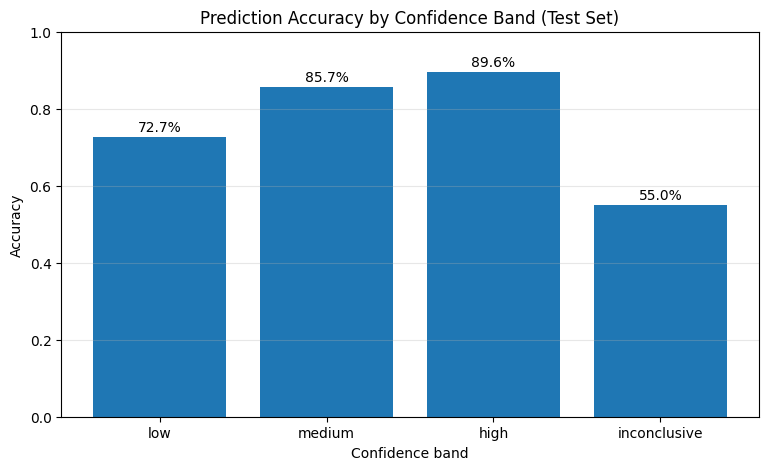

In [2]:

# Remove summary rows because we only want individual confidence bands
test_plot = bands_test[
    bands_test["band"].isin(["low", "medium", "high", "inconclusive"])
].copy()

plt.figure(figsize=(9, 5))

bars = plt.bar(
    test_plot["band"],
    test_plot["accuracy"]
)

plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.xlabel("Confidence band")
plt.title("Prediction Accuracy by Confidence Band (Test Set)")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, test_plot["accuracy"]):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.015,
        f"{value:.1%}",
        ha="center"
    )

plt.show()



## 3. Abstention Analysis

The system does not have to classify every submission.

When the calibrated probability falls within the inconclusive zone, the system abstains from making a definitive prediction.

This creates a trade-off:

- Lower coverage means the system answers fewer submissions.
- Higher coverage means the system answers more submissions, but may include less reliable predictions.

We evaluate whether abstaining from inconclusive predictions improves the accuracy of the remaining predictions.


In [3]:

# Compare overall performance with and without abstention

test_all = bands_test[
    bands_test["band"] == "all files"
].iloc[0]

test_answered = bands_test[
    bands_test["band"] == "answered (not inconclusive)"
].iloc[0]

coverage = test_answered["files"] / test_all["files"]

print(f"Total submissions: {int(test_all['files'])}")
print(f"Submissions answered: {int(test_answered['files'])}")
print(f"Coverage: {coverage:.1%}")
print(f"Accuracy on all submissions: {test_all['accuracy']:.1%}")
print(f"Accuracy on answered submissions: {test_answered['accuracy']:.1%}")
print(f"Abstention rate: {1 - coverage:.1%}")


Total submissions: 1009
Submissions answered: 860
Coverage: 85.2%
Accuracy on all submissions: 78.5%
Accuracy on answered submissions: 82.6%
Abstention rate: 14.8%



## 4. Validation vs Test Performance

We compare validation and test results to check whether the confidence strategy generalizes to unseen data.

The validation set was used to fit the calibration parameters and determine confidence thresholds. The test set was kept separate to evaluate the final performance of the approach.


In [4]:

# Compare accuracy and coverage across validation and test sets

def get_summary(df):
    all_files = df[df["band"] == "all files"].iloc[0]
    answered = df[
        df["band"] == "answered (not inconclusive)"
    ].iloc[0]

    return {
        "Set": "Validation" if df is bands_val else "Test",
        "Total files": int(all_files["files"]),
        "Coverage": answered["share"],
        "Abstention rate": 1 - answered["share"],
        "Accuracy (all)": all_files["accuracy"],
        "Accuracy (answered)": answered["accuracy"]
    }

comparison = pd.DataFrame([
    get_summary(bands_val),
    get_summary(bands_test)
])

display(
    comparison.style.format({
        "Coverage": "{:.1%}",
        "Abstention rate": "{:.1%}",
        "Accuracy (all)": "{:.1%}",
        "Accuracy (answered)": "{:.1%}"
    })
)


,Set,Total files,Coverage,Abstention rate,Accuracy (all),Accuracy (answered)
0,Validation,1005,85.0%,15.0%,79.0%,82.4%
1,Test,1009,85.2%,14.8%,78.5%,82.6%



## 5. Final Conclusions

The confidence evaluation produced the following findings:

1. **Calibration improved probability reliability.** On the test set, ECE decreased from 0.1077 to 0.0478, while the Brier score decreased from 0.1690 to 0.1545.

2. **Discrimination remained unchanged.** AUC stayed at 0.8020 because probability calibration did not change the model's ranking of submissions.

3. **Confidence bands showed meaningful differences.** Test accuracy increased from 72.7% in the low-confidence band to 89.6% in the high-confidence band.

4. **Abstention improved answered-prediction accuracy.** By abstaining on 14.8% of test submissions, accuracy on the remaining predictions increased from 78.5% to 82.6%.

5. **The results were consistent across validation and test data.** Coverage and answered-prediction accuracy were similar across both sets.

### Limitations

- Calibration improves probability reliability but does not eliminate classification errors.
- The inconclusive group still contains useful predictions, but their reliability is relatively low.
- High-confidence AI precision was 100% on the test set, but this represents only 41 AI predictions. It should not be interpreted as a guarantee of correctness.
- The model can still confidently misclassify some AI-generated submissions.

### Overall Conclusion

The confidence layer makes the detection system more informative by communicating prediction reliability and allowing it to abstain when uncertain. It improves the quality of definitive predictions, although it does not eliminate the underlying model's errors.


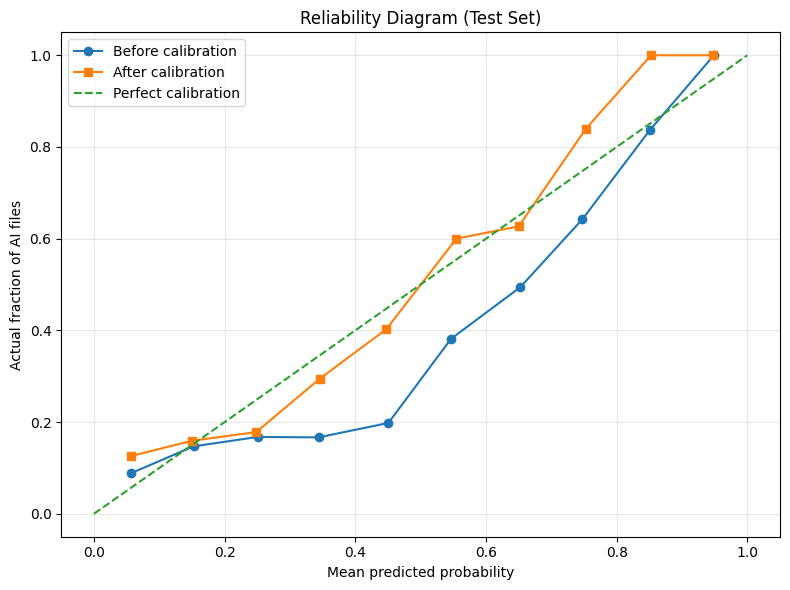

Test files: 1009
Calibration parameters: {'coef': 1.0253460240149994, 'intercept': -0.6368389000262481}


In [6]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from sklearn.calibration import calibration_curve

# Locate the project root automatically
ROOT = Path.cwd()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Load saved predictions and calibration parameters
preds = pd.read_parquet(ROOT / "results" / "preds_feat_xgb.parquet")
test = preds[preds["split"] == "test"].copy()

with open(ROOT / "models" / "calibration.json") as f:
    cal = json.load(f)

# Reproduce the exact Platt scaling used in confidence.py
EPS = 1e-6

def logit(p):
    p = np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)
    return np.log(p / (1 - p))

def apply_platt(scores):
    z = cal["coef"] * logit(scores) + cal["intercept"]
    return 1.0 / (1.0 + np.exp(-z))

# Raw and calibrated probabilities
y_true = test["y_true"].to_numpy()
p_raw = test["y_score"].to_numpy()
p_cal = apply_platt(p_raw)

# Calculate reliability curves using 10 uniform bins
actual_raw, predicted_raw = calibration_curve(
    y_true, p_raw, n_bins=10, strategy="uniform"
)

actual_cal, predicted_cal = calibration_curve(
    y_true, p_cal, n_bins=10, strategy="uniform"
)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    predicted_raw, actual_raw,
    marker="o", label="Before calibration"
)

plt.plot(
    predicted_cal, actual_cal,
    marker="s", label="After calibration"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--", label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Actual fraction of AI files")
plt.title("Reliability Diagram (Test Set)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Test files:", len(test))
print("Calibration parameters:", cal)


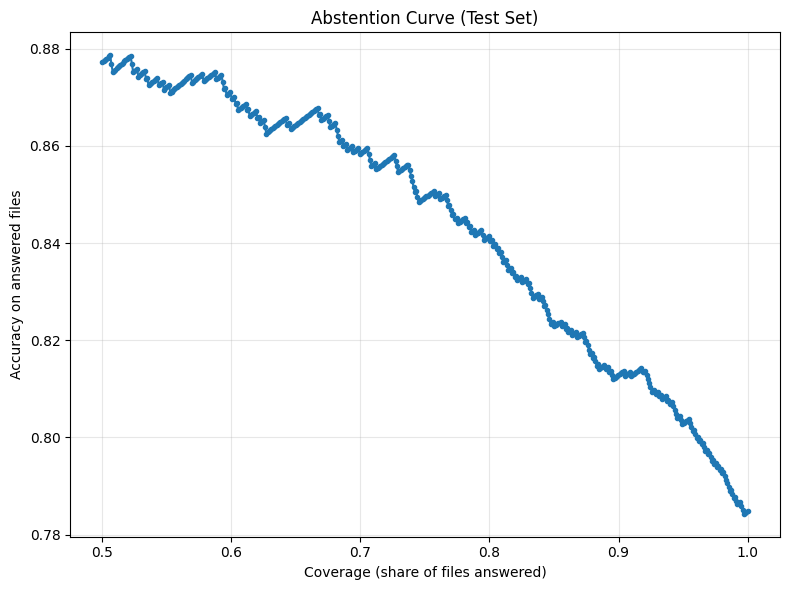

Total test files: 1009
Accuracy with no abstention: 78.5%
Accuracy after 50% abstention: 87.7%

Saved:
c:\Users\yassi\OneDrive\Documents\GitHub\WhoWroteIt-\results\phase45\abstention_curve_test.csv
c:\Users\yassi\OneDrive\Documents\GitHub\WhoWroteIt-\results\phase45\abstention_curve_test.png


In [7]:

import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Find project root
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Load predictions and saved calibration settings
preds = pd.read_parquet(ROOT / "results" / "preds_feat_xgb.parquet")
test = preds[preds["split"] == "test"].copy()

with open(ROOT / "models" / "calibration.json") as f:
    cal = json.load(f)

with open(ROOT / "models" / "confidence_cuts.json") as f:
    cuts = json.load(f)

# Apply the exact Platt scaling used by confidence.py
EPS = 1e-6

def logit(p):
    p = np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)
    return np.log(p / (1 - p))

def apply_platt(scores):
    z = cal["coef"] * logit(scores) + cal["intercept"]
    return 1 / (1 + np.exp(-z))

p_cal = apply_platt(test["y_score"].to_numpy())
y_true = test["y_true"].to_numpy()

# Use the calibrated threshold; calibration does not change the verdict
t_cal = cuts["t_cal"]
y_pred = (p_cal >= t_cal).astype(int)

# Confidence in the predicted verdict itself
verdict_confidence = np.where(y_pred == 1, p_cal, 1 - p_cal)

# Sort files from least confident to most confident
order = np.argsort(verdict_confidence)
y_true_sorted = y_true[order]
y_pred_sorted = y_pred[order]

# Gradually abstain on the least-confident files
max_abstain = int(0.50 * len(test))
rows = []

for n_abstain in range(max_abstain + 1):
    remaining_true = y_true_sorted[n_abstain:]
    remaining_pred = y_pred_sorted[n_abstain:]

    coverage = len(remaining_true) / len(test)
    accuracy = np.mean(remaining_true == remaining_pred)

    rows.append({
        "abstained_files": n_abstain,
        "abstention_rate": n_abstain / len(test),
        "coverage": coverage,
        "accuracy": accuracy
    })

abstention_curve = pd.DataFrame(rows)

# Save numerical results
out_dir = ROOT / "results" / "phase45"
out_dir.mkdir(parents=True, exist_ok=True)

abstention_curve.to_csv(
    out_dir / "abstention_curve_test.csv",
    index=False
)

# Plot accuracy against coverage
plt.figure(figsize=(8, 6))

plt.plot(
    abstention_curve["coverage"],
    abstention_curve["accuracy"],
    marker="o",
    markersize=3
)

plt.xlabel("Coverage (share of files answered)")
plt.ylabel("Accuracy on answered files")
plt.title("Abstention Curve (Test Set)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    out_dir / "abstention_curve_test.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Total test files:", len(test))
print("Accuracy with no abstention:",
      f"{abstention_curve.iloc[0]['accuracy']:.1%}")
print("Accuracy after 50% abstention:",
      f"{abstention_curve.iloc[-1]['accuracy']:.1%}")
print("\nSaved:")
print(out_dir / "abstention_curve_test.csv")
print(out_dir / "abstention_curve_test.png")


In [9]:
from pathlib import Path
import sys
import json
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb

# Locate project root
ROOT = Path.cwd()
if not (ROOT / "models").exists():
    ROOT = ROOT.parent

# IMPORTANT: Make project modules available before loading the model
sys.path.insert(0, str(ROOT / "src"))

print("Project root:", ROOT)
print("Source folder:", ROOT / "src")

# Load model
best = joblib.load(ROOT / "models" / "best.joblib")
pipe = best["pipeline"]
feat = pipe.named_steps["feat"]
clf = pipe.named_steps["clf"]
cols = list(feat.cols_)

# Load predictions and test features
preds = pd.read_parquet(ROOT / "results" / "preds_feat_xgb.parquet")
preds_test = preds[preds["split"] == "test"].copy()

features_test = pd.read_parquet(
    ROOT / "data" / "features_aig" / "features_test.parquet"
)

test_df = preds_test.merge(
    features_test,
    on="sample_id",
    how="inner",
    validate="one_to_one"
)

print("Prediction test rows:", len(preds_test))
print("Matched test rows:", len(test_df))

assert len(test_df) == len(preds_test)
assert all(c in test_df.columns for c in cols)

X_test = test_df[cols].to_numpy(dtype=float)

contributions = clf.get_booster().predict(
    xgb.DMatrix(X_test),
    pred_contribs=True
)

print("Model features:", len(cols))
print("SHAP output shape:", contributions.shape)

assert contributions.shape[1] == len(cols) + 1

Project root: c:\Users\yassi\OneDrive\Documents\GitHub\WhoWroteIt-
Source folder: c:\Users\yassi\OneDrive\Documents\GitHub\WhoWroteIt-\src
Prediction test rows: 1009
Matched test rows: 1009
Model features: 90
SHAP output shape: (1009, 91)


C:\Users\yassi\AppData\Roaming\Python\Python314\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.7.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [10]:
# Load Phase 2 class means and feature groups.
ranking = pd.read_csv(
    ROOT / "results" / "phase2" / "feature_ranking_all.csv"
).set_index("feature")

dictionary = pd.read_csv(
    ROOT / "data" / "feature_dictionary.csv"
).set_index("feature")

mean_human = ranking["mean_human"].to_dict()
mean_ai = ranking["mean_ai"].to_dict()
groups = dictionary["group"].to_dict()

results = []

for i in range(len(test_df)):
    row = X_test[i]
    contrib = contributions[i]

    # Match evidence.py: examine features in descending absolute SHAP value.
    selected = 0

    for j in np.argsort(-np.abs(contrib[:-1])):
        name = cols[j]
        value = row[j]

        if abs(contrib[j]) < 1e-9:
            break

        if np.isnan(value) or name == "ast_ok":
            continue

        ast_ok = (
            bool(row[cols.index("ast_ok")])
            if "ast_ok" in cols
            else bool(test_df.iloc[i]["ast_ok"])
        )

        if not ast_ok and groups.get(name) == "ast":
            continue

        if name not in mean_human or name not in mean_ai:
            continue

        # Direction indicated by SHAP.
        points = "AI" if contrib[j] > 0 else "human"

        # Which class mean is the actual value closer to?
        closer_to = (
            "human"
            if abs(value - mean_human[name]) < abs(value - mean_ai[name])
            else "AI"
        )

        results.append({
            "sample_id": test_df.iloc[i]["sample_id"],
            "feature": name,
            "shap_direction": points,
            "class_mean_direction": closer_to,
            "agrees": points == closer_to,
            "shap_contribution": float(contrib[j])
        })

        selected += 1
        if selected == 5:
            break

agreement_df = pd.DataFrame(results)

print("Total selected feature explanations:", len(agreement_df))
print("Agreements:", agreement_df["agrees"].sum())
print("Disagreements:", (~agreement_df["agrees"]).sum())
print(
    "Overall direction agreement:",
    f"{agreement_df['agrees'].mean() * 100:.2f}%"
)

Total selected feature explanations: 5045
Agreements: 4245
Disagreements: 800
Overall direction agreement: 84.14%


In [11]:
feature_summary = (
    agreement_df.groupby("feature")
    .agg(
        appearances=("agrees", "size"),
        agreements=("agrees", "sum"),
        disagreements=("agrees", lambda x: (~x).sum()),
        agreement_rate=("agrees", "mean")
    )
    .reset_index()
    .sort_values("agreement_rate", ascending=False)
)

feature_summary["agreement_rate"] = (
    feature_summary["agreement_rate"] * 100
).round(2)

print(feature_summary.to_string(index=False))

# Save the detailed and summarized results.
out_dir = ROOT / "results" / "phase45"
out_dir.mkdir(parents=True, exist_ok=True)

agreement_df.to_csv(
    out_dir / "direction_agreement_details.csv",
    index=False
)

feature_summary.to_csv(
    out_dir / "direction_agreement_summary.csv",
    index=False
)

print("\nSaved direction-agreement CSV files.")

               feature  appearances  agreements  disagreements  agreement_rate
    ast_frac_Attribute           30          30              0          100.00
       ast_frac_BoolOp            4           4              0          100.00
     ast_frac_Continue           32          32              0          100.00
        ast_frac_IfExp           20          20              0          100.00
  ast_frac_FunctionDef           77          77              0          100.00
          ast_frac_For           16          16              0          100.00
         ast_frac_Expr           33          33              0          100.00
      ast_frac_UnaryOp            3           3              0          100.00
        ast_frac_Tuple            1           1              0          100.00
       ast_frac_Return           30          30              0          100.00
        ast_frac_Slice           37          37              0          100.00
       ast_frac_Lambda            7           7     

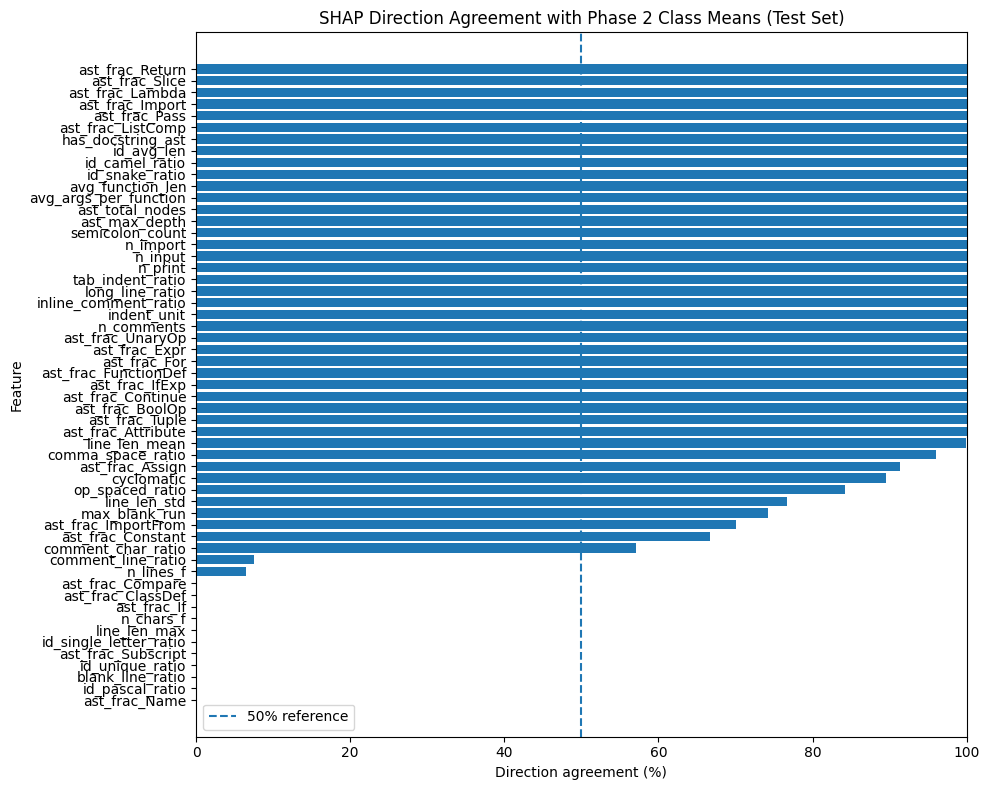

In [12]:
import matplotlib.pyplot as plt

plot_df = feature_summary.sort_values("agreement_rate")

plt.figure(figsize=(10, 8))

plt.barh(
    plot_df["feature"],
    plot_df["agreement_rate"]
)

plt.axvline(
    50,
    linestyle="--",
    label="50% reference"
)

plt.xlabel("Direction agreement (%)")
plt.ylabel("Feature")
plt.title("SHAP Direction Agreement with Phase 2 Class Means (Test Set)")
plt.xlim(0, 100)
plt.legend()
plt.tight_layout()

plt.savefig(
    out_dir / "direction_agreement_test.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
total = len(agreement_df)
agreements = int(agreement_df["agrees"].sum())
disagreements = total - agreements
overall_rate = agreements / total * 100

overall_summary = pd.DataFrame([{
    "test_files": len(test_df),
    "feature_explanations": total,
    "agreements": agreements,
    "disagreements": disagreements,
    "overall_agreement_percent": round(overall_rate, 2)
}])

display(overall_summary)

overall_summary.to_csv(
    out_dir / "direction_agreement_overall.csv",
    index=False
)

,test_files,feature_explanations,agreements,disagreements,overall_agreement_percent
0,1009,5045,4245,800,84.14
